# ViSpeech — phân tích dữ liệu phục vụ luận văn

**Mục tiêu:** mô tả đúng dữ liệu đang sử dụng và giải thích dữ liệu đó đặt ra yêu cầu gì cho việc huấn luyện, đánh giá mô hình phân loại phương ngữ Bắc–Trung–Nam.

Mỗi phần đi theo thứ tự **câu hỏi → bảng/hình → nhận xét từ số liệu → ý nghĩa với mô hình**. Notebook tham khảo VIVOS được dùng để học cách chia từng bước ngắn; số liệu, bộ chia và đặc trưng của VIVOS không được dùng thay cho ViSpeech.

| Phần | Câu hỏi cần trả lời | Đưa vào luận ở đâu? |
|---|---|---|
| 1–2. Nguồn và bộ chia | Có bao nhiêu file, người nói; mỗi tập dùng làm gì? | Chương Dữ liệu, bảng tổng quan |
| 3. Phân bố ba miền | Miền nào ít dữ liệu hơn; train và validation có tỉ lệ tương tự không? | Chương Dữ liệu, hình chính |
| 4. Giới tính | Trong từng miền, hai giới có được đại diện tương đương không? | Bảng/hình bổ sung nếu cần |
| 5. Người nói | Nhiều file có đồng nghĩa nhiều người nói; các tập có trùng người không? | Chương Dữ liệu và giới hạn đánh giá |
| 6. Sampler | Dữ liệu gốc và dữ liệu mô hình gặp khi train khác nhau thế nào? | Thiết lập thực nghiệm |
| 7. Thời lượng (tùy chọn) | Audio dài/ngắn ra sao so với đầu vào mô hình? | Dữ liệu và tiền xử lý |
| 8. Tổng hợp | Kết quả nào đã quan sát, điều gì còn phải kiểm chứng? | Bản nháp để biên tập vào luận |
| Phụ lục. Paper | Số liệu cục bộ có khớp bài báo không? | Ghi chú nguồn và phụ lục |

**Cách chạy trong VS Code:** chọn kernel `.venv/Scripts/python.exe` của dự án ViSpeech, giữ `READ_AUDIO_INFO = False`, rồi **Run All**. Không cần chạy file train hoặc evaluate để dùng notebook này. Không dùng GPU; phần mặc định chỉ đọc metadata và danh sách chia tập. Các ô chưa được thực thi.

Khi bạn chạy, bảng CSV, hình PNG 300 dpi/PDF và bản nháp Markdown được lưu vào thư mục mới `Report/Dataset_Analysis/<thời điểm>/`. Chỉ phần thời lượng cần đọc các file audio; nên bật sau khi train xong.

Nguồn: [Nguyen et al. (2024), Gender and Dialect Classification for the Vietnamese Language](https://aclanthology.org/2024.paclic-1.39.pdf), mục 3.4, 4.1, Bảng 2–3. **Phân tích mô tả dataset là cơ sở thiết kế thực nghiệm, chưa phải đóng góp phương pháp mới.**

In [1]:
from pathlib import Path
from datetime import datetime
from itertools import combinations
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

READ_AUDIO_INFO = False  # True: đọc thông tin của mọi audio; nên để sau khi train.
CHECK_AUDIO_PATHS = False  # True: kiểm tra file tồn tại, không giải mã audio.

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates
             if (p / 'Data/ViSpeech/metadata/trainset.csv').is_file()
             and (p / 'Code/ViSpeech/dataset/train.txt').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong thư mục dự án LuanVan01.')
PROJECT = ROOT / 'Code/ViSpeech'
DATA = ROOT / 'Data/ViSpeech'
OUT = ROOT / 'Report/Dataset_Analysis' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True, exist_ok=False)

CORPUS_NAMES = {'trainset': 'Train gốc', 'clean_testset': 'Test sạch', 'noisy_testset': 'Test nhiễu'}
SPLIT_FILES = {'Train': 'train.txt', 'Validation': 'validation.txt',
               'Test sạch': 'clean_testset.txt', 'Test nhiễu': 'noisy_testset.txt'}
REGIONS = ['North', 'Central', 'South']
REGION_NAMES = {'North': 'Bắc', 'Central': 'Trung', 'South': 'Nam'}
SPLITS = list(SPLIT_FILES)
hashes = {}

def file_hash(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def save_table(name, table, index=False):
    # Lưu đủ dữ liệu; chỉ hiển thị bảng ngắn, không tràn hàng nghìn dòng.
    table.to_csv(OUT / (name + '.csv'), index=index, encoding='utf-8-sig')
    visible = table.drop(columns=['speaker_ids'], errors='ignore').copy()
    for column, labels in [('dialect', REGION_NAMES), ('gender', {'Female': 'Nữ', 'Male': 'Nam'})]:
        if column in visible.columns:
            visible[column] = visible[column].replace(labels)
    if visible.empty:
        print('Không có trường hợp cần liệt kê:', name)
    else:
        display(visible.rename(columns=DISPLAY_NAMES).head(12))
        if len(visible) > 12:
            print(f'Hiển thị 12/{len(visible)} dòng. Bảng đầy đủ: {name}.csv')

def show_figure(name, figure):
    figure.savefig(OUT / (name + '.png'), dpi=300, bbox_inches='tight')
    figure.savefig(OUT / (name + '.pdf'), bbox_inches='tight')
    plt.show()
    plt.close(figure)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Dự án:', ROOT)
print('Kết quả xuất vào:', OUT)
print('Notebook không import PyTorch, không chạy model.')


COLORS = ['#3478A5', '#D18B35', '#43936C']  # Bắc, Trung, Nam, thống nhất mọi hình.
DISPLAY_NAMES = {
    'corpus': 'Tập gốc', 'split': 'Tập thực nghiệm', 'so_file': 'Số file',
    'so_nguoi_noi': 'Số người nói', 'gender': 'Giới tính', 'dialect': 'Phương ngữ',
    'tap_A': 'Tập A', 'tap_B': 'Tập B', 'so_file_trung': 'File trùng',
    'so_speaker_trung': 'Người nói chung',
    'file_A_thuoc_speaker_chung': 'File A của người nói chung',
    'file_B_thuoc_speaker_chung': 'File B của người nói chung',
    'count': 'Số người nói', 'min': 'Nhỏ nhất', 'median': 'Trung vị',
    'mean': 'Trung bình', 'max': 'Lớn nhất',
    'ty_le_trong_train_goc_pct': 'Tỉ lệ trong train gốc (%)',
    'Female': 'Nữ (%)', 'Male': 'Nam (%)', 'audio_name': 'Tên file', 'speaker': 'Mã người nói',
    'so_nhan_phuong_ngu': 'Số nhãn phương ngữ', 'so_nhan_gioi_tinh': 'Số nhãn giới tính',
    'paper_files': 'Số file (paper)', 'actual_files': 'Số file (metadata)',
    'paper_speakers': 'Người nói (paper)', 'actual_speakers': 'Người nói (metadata)',
    'file_difference': 'Chênh lệch file', 'speaker_difference': 'Chênh lệch người nói',
    'difference': 'Chênh lệch file', 'duration_seconds': 'Thời lượng (giây)',
    'sample_rate': 'Tần số lấy mẫu (Hz)', 'channels': 'Số kênh', 'error': 'Lỗi đọc',
    'total_files': 'Tổng file', 'measured_files': 'File đo được',
    'total_measured_seconds': 'Tổng giây đo được', 'measured_hours': 'Tổng giờ đo được',
    'min_seconds': 'Ngắn nhất (s)', 'mean_seconds': 'Trung bình (s)',
    'median_seconds': 'Trung vị (s)', 'max_seconds': 'Dài nhất (s)',
    'coverage_pct': 'Độ phủ phép đo (%)', 'shorter_pct': 'Ngắn hơn đầu vào (%)',
    'longer_pct': 'Dài hơn đầu vào (%)'}
insights = {}

def explain(key, observation, implication, limit):
    insights[key] = (observation, implication, limit)
    display(Markdown(f'**Kết quả đọc được:** {observation}\n\n'
                     f'**Ý nghĩa với mô hình/đánh giá:** {implication}\n\n'
                     f'**Chưa thể kết luận:** {limit}'))

def label_bars(ax, percent=False, inside=False):
    for container in ax.containers:
        for bar in container:
            height = bar.get_height()
            if not np.isfinite(height) or height <= 0:
                continue
            text = f'{height:.1f}%' if percent else f'{height:,.0f}'
            y = bar.get_y() + height / 2 if inside else bar.get_y() + height
            ax.annotate(text, (bar.get_x() + bar.get_width() / 2, y),
                        xytext=(0, 0 if inside else 3), textcoords='offset points',
                        ha='center', va='center' if inside else 'bottom',
                        color='white' if inside else '#222222', fontsize=9)
    if not inside:
        ax.set_ylim(0, ax.get_ylim()[1] * 1.17)

Dự án: c:\Users\Uyen\Documents\Master\LuanVan01
Kết quả xuất vào: c:\Users\Uyen\Documents\Master\LuanVan01\Report\Dataset_Analysis\20261019_110129_396978
Notebook không import PyTorch, không chạy model.


## 1. Dữ liệu có những thông tin gì?

**Phân tích gì?** Đếm file và mã người nói từ ba metadata gốc, kiểm tra nhãn bị thiếu hoặc một mã người nói có nhiều nhãn.

**Vì sao cần?** Đây là nguồn của mọi bảng trong luận. Một người nói có thể tạo nhiều file; một file có thể được sampler lấy nhiều lần. Ba đại lượng này không thể dùng thay nhau.

**Cách trình bày:** bảng nhỏ phù hợp hơn biểu đồ ở đây vì cần tra cứu số chính xác. `Train gốc` chưa tách validation. Tổng người nói phải đếm mã duy nhất trên toàn bộ dữ liệu, không cộng các hàng.

In [2]:
parts = []
for folder, name in CORPUS_NAMES.items():
    path = DATA / 'metadata' / (folder + '.csv')
    hashes[str(path.relative_to(ROOT))] = file_hash(path)
    frame = pd.read_csv(path, dtype=str, encoding='utf-8-sig')
    required = ['audio_name', 'dialect', 'gender', 'speaker']
    if not set(required).issubset(frame.columns):
        raise ValueError(f'Thiếu cột trong {path.name}')
    if frame[required].isna().any().any():
        raise ValueError(f'Nhãn hoặc mã speaker bị thiếu: {path.name}')
    for column in required:
        frame[column] = frame[column].str.strip()
    if frame[required].eq('').any().any():
        raise ValueError(f'Có nhãn trống: {path.name}')
    if not frame.dialect.isin(REGIONS).all() or not frame.gender.isin(['Female', 'Male']).all():
        raise ValueError(f'Nhãn không hợp lệ: {path.name}')
    frame['corpus'] = name
    frame['audio_path'] = frame.audio_name.map(lambda n: str((DATA / folder / n).resolve()))
    parts.append(frame)

metadata = pd.concat(parts, ignore_index=True)
duplicates = metadata[metadata.audio_name.duplicated(keep=False)]
if not duplicates.empty:
    display(duplicates)
    raise ValueError('Tên audio trùng; cần kiểm tra trước khi ghép metadata.')
save_table('01_corpus_overview',
           metadata.groupby('corpus', sort=False).agg(
               so_file=('audio_name', 'size'), so_nguoi_noi=('speaker', 'nunique')).reset_index())
print('Tổng file duy nhất:', metadata.audio_name.nunique())
print('Tổng mã người nói duy nhất:', metadata.speaker.nunique())
print('Không cộng số người nói các tập để suy ra tổng, vì có thể có người xuất hiện ở nhiều tập.')

speaker_labels = metadata.groupby('speaker').agg(
    so_nhan_phuong_ngu=('dialect', 'nunique'), so_nhan_gioi_tinh=('gender', 'nunique'))
ambiguous_speakers = speaker_labels[
    speaker_labels.so_nhan_phuong_ngu.gt(1) | speaker_labels.so_nhan_gioi_tinh.gt(1)]
save_table('02_speakers_multiple_labels', ambiguous_speakers.reset_index())
if not ambiguous_speakers.empty:
    print('Cần rà soát speaker nhiều nhãn. Không tự đổi nhãn chỉ dựa trên kiểm tra này.')

explain('Nguồn dữ liệu',
        f'Metadata có {len(metadata):,} file và {metadata.speaker.nunique():,} mã người nói duy nhất; '
        f'{len(ambiguous_speakers)} mã có nhiều nhãn phương ngữ hoặc giới tính.',
        'Số file thể hiện quy mô mẫu; số người nói bổ sung thông tin về mức đa dạng giọng nói.',
        'Nhiều file không tự bảo đảm nhiều giọng độc lập; kiểm tra metadata không xác nhận mọi nhãn đều đúng khi nghe.')

,Tập gốc,Số file,Số người nói
0,Train gốc,8166,310
1,Test sạch,1500,84
2,Test nhiễu,1020,66


Tổng file duy nhất: 10686
Tổng mã người nói duy nhất: 449
Không cộng số người nói các tập để suy ra tổng, vì có thể có người xuất hiện ở nhiều tập.
Không có trường hợp cần liệt kê: 02_speakers_multiple_labels


**Kết quả đọc được:** Metadata có 10,686 file và 449 mã người nói duy nhất; 0 mã có nhiều nhãn phương ngữ hoặc giới tính.

**Ý nghĩa với mô hình/đánh giá:** Số file thể hiện quy mô mẫu; số người nói bổ sung thông tin về mức đa dạng giọng nói.

**Chưa thể kết luận:** Nhiều file không tự bảo đảm nhiều giọng độc lập; kiểm tra metadata không xác nhận mọi nhãn đều đúng khi nghe.

## 2. Train, validation và test được dùng như thế nào?

**Phân tích gì?** Đọc đúng bốn danh sách đang dùng, đối chiếu đường dẫn/nhãn với metadata, kiểm tra train–validation không trùng tên file và ghép lại đủ train gốc.

**Vì sao cần?** Số liệu luận văn phải mô tả đúng thí nghiệm đang chạy. Audio validation nằm trong thư mục `trainset/` không đồng nghĩa file đó nằm trong danh sách Train.

| Tập | Vai trò |
|---|---|
| Train | Cập nhật trọng số mô hình |
| Validation | Theo dõi và chọn checkpoint; thiết lập hiện tại vẫn mỗi **306 bước** |
| Test sạch / Test nhiễu | Đánh giá sau khi chốt phương pháp; không dùng chọn checkpoint |

**Cách đọc bảng:** hai hàng Train và Validation là phần tách từ Train gốc, không cộng thêm Train gốc lần nữa. Hai tập test là các tập khác nhau; chênh lệch accuracy giữa chúng không tự đo tác động của việc thêm nhiễu lên cùng một câu nói.

Mã nhãn gốc: nữ Bắc/Trung/Nam = 0/1/2, nam Bắc/Trung/Nam = 3/4/5; bài toán phương ngữ dùng `label % 3`.

In [3]:
split_parts = []
region_id = {'North': 0, 'Central': 1, 'South': 2}
gender_id = {'Female': 0, 'Male': 1}
for split, filename in SPLIT_FILES.items():
    path = PROJECT / 'dataset' / filename
    hashes[str(path.relative_to(ROOT))] = file_hash(path)
    frame = pd.read_csv(path, header=None, names=['listed_path', 'label'], encoding='utf-8-sig')
    if frame.empty or frame.isna().any().any() or not frame.label.isin(range(6)).all():
        raise ValueError(f'Danh sách rỗng hoặc nhãn sai: {filename}')
    frame['audio_name'] = frame.listed_path.map(lambda p: Path(p.replace('\\', '/')).name)
    frame['listed_absolute_path'] = frame.listed_path.map(lambda p: str((PROJECT / p).resolve()))
    if frame.audio_name.duplicated().any():
        raise ValueError(f'File bị lặp trong {filename}')
    joined = frame.merge(metadata, on='audio_name', how='left', validate='one_to_one', indicator=True)
    if not joined['_merge'].eq('both').all():
        display(joined[joined['_merge'].ne('both')])
        raise ValueError(f'Có file không tìm thấy metadata: {filename}')
    expected_label = joined.gender.map(gender_id) * 3 + joined.dialect.map(region_id)
    if not joined.label.eq(expected_label).all():
        display(joined[joined.label.ne(expected_label)])
        raise ValueError(f'Nhãn danh sách khác metadata: {filename}')
    if not joined.listed_absolute_path.str.casefold().eq(joined.audio_path.str.casefold()).all():
        raise ValueError(f'Đường dẫn danh sách khác vị trí metadata dự kiến: {filename}')
    joined['split'] = split
    split_parts.append(joined.drop(columns='_merge'))

splits = pd.concat(split_parts, ignore_index=True)
sets = {name: set(splits.loc[splits.split.eq(name), 'audio_name']) for name in SPLITS}
train_original = set(metadata.loc[metadata.corpus.eq('Train gốc'), 'audio_name'])
if sets['Train'] & sets['Validation']:
    raise ValueError('Train và Validation trùng tên file.')
if sets['Train'] | sets['Validation'] != train_original:
    raise ValueError('Train + Validation chưa khớp train gốc.')
for name in ['Test sạch', 'Test nhiễu']:
    if sets[name] != set(metadata.loc[metadata.corpus.eq(name), 'audio_name']):
        raise ValueError(f'Danh sách {name} khác metadata.')
overview = splits.groupby('split', sort=False).agg(
    so_file=('audio_name', 'size'), so_nguoi_noi=('speaker', 'nunique')).reindex(SPLITS)
overview['ty_le_trong_train_goc_pct'] = [
    len(sets[name]) / len(train_original) * 100 if name in ['Train', 'Validation'] else np.nan
    for name in SPLITS]
save_table('03_experimental_splits', overview.reset_index().round(2))

if CHECK_AUDIO_PATHS:
    missing_audio = metadata.loc[~metadata.audio_path.map(lambda p: Path(p).is_file())]
    save_table('04_missing_audio_paths', missing_audio[['audio_name', 'audio_path']])
else:
    print('Chưa kiểm tra file audio tồn tại; các kiểm tra trên dùng danh sách và metadata.')

thesis_overview = overview[['so_file', 'so_nguoi_noi']].rename(
    columns={'so_file': 'Số file', 'so_nguoi_noi': 'Số người nói'})
thesis_overview['Vai trò'] = ['Huấn luyện', 'Chọn checkpoint', 'Đánh giá sạch', 'Đánh giá nhiễu']
save_table('thesis_table01_dataset_overview', thesis_overview.rename_axis('Tập').reset_index())
explain('Bộ chia',
        f'Train gồm {len(sets["Train"]):,} file, validation {len(sets["Validation"]):,} file; '
        'hai danh sách không trùng tên file và ghép lại bằng train gốc.',
        'Có thể báo cáo rõ dữ liệu dùng học và dữ liệu dùng chọn checkpoint; giữ nguyên các danh sách khi đối chứng sampler.',
        'Không trùng tên file chưa đồng nghĩa không trùng người nói. Phần 5 kiểm tra riêng điều đó.')

,Tập thực nghiệm,Số file,Số người nói,Tỉ lệ trong train gốc (%)
0,Train,6941,310,85.0
1,Validation,1225,275,15.0
2,Test sạch,1500,84,NaN
3,Test nhiễu,1020,66,NaN


Chưa kiểm tra file audio tồn tại; các kiểm tra trên dùng danh sách và metadata.


,Tập,Số file,Số người nói,Vai trò
0,Train,6941,310,Huấn luyện
1,Validation,1225,275,Chọn checkpoint
2,Test sạch,1500,84,Đánh giá sạch
3,Test nhiễu,1020,66,Đánh giá nhiễu


**Kết quả đọc được:** Train gồm 6,941 file, validation 1,225 file; hai danh sách không trùng tên file và ghép lại bằng train gốc.

**Ý nghĩa với mô hình/đánh giá:** Có thể báo cáo rõ dữ liệu dùng học và dữ liệu dùng chọn checkpoint; giữ nguyên các danh sách khi đối chứng sampler.

**Chưa thể kết luận:** Không trùng tên file chưa đồng nghĩa không trùng người nói. Phần 5 kiểm tra riêng điều đó.

## 3. Ba miền có cân bằng về số file không?

**Phân tích gì?** Số file và tỉ lệ Bắc–Trung–Nam trong từng tập; mức chênh giữa lớp nhiều nhất/ít nhất; chênh lệch tỉ lệ train–validation.

**Vì sao cần?** Khi học theo phân bố file gốc, lớp nhiều file có thể đóng góp nhiều lượt cập nhật hơn. Cần biết mức lệch thực tế trước khi nói sampler đang bù mất cân bằng hay ưu tiên một miền.

**Vì sao dùng biểu đồ cột?** Miền là ba nhóm rời rạc: cột đặt cạnh nhau giúp so sánh số lượng trực tiếp. Hình cột chồng 100% giúp so sánh tỉ lệ dù Train lớn hơn Test. Màu Bắc–Trung–Nam được giữ giống nhau ở mọi hình; nhãn số cho phép đọc mà không ước lượng chiều cao.

dialect,Tập thực nghiệm,Bắc,Trung,Nam
0,Train,2392,2101,2448
1,Validation,422,371,432
2,Test sạch,500,500,500
3,Test nhiễu,340,340,340


dialect,Tập thực nghiệm,Bắc,Trung,Nam
0,Train,34.46,30.27,35.27
1,Validation,34.45,30.29,35.27
2,Test sạch,33.33,33.33,33.33
3,Test nhiễu,33.33,33.33,33.33


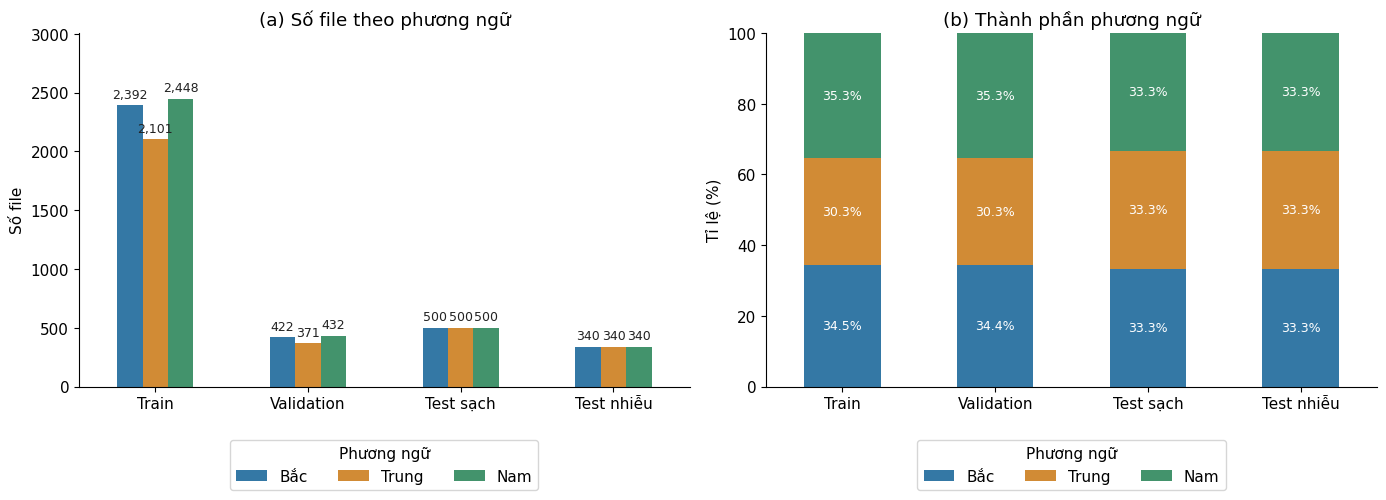

**Kết quả đọc được:** Train: Bắc 2,392 file (34.46%), Trung 2,101 file (30.27%), Nam 2,448 file (35.27%). Lớp nhiều nhất/ít nhất = 1.17 lần. Chênh lệch tỉ lệ train–validation lớn nhất là 0.02 điểm phần trăm.

**Ý nghĩa với mô hình/đánh giá:** Báo cáo cả accuracy, macro-F1 và recall từng miền để thấy lớp nào bị bỏ sót; dùng bảng sampler ở phần 6 để phân biệt tỉ lệ file với tỉ lệ lượt học.

**Chưa thể kết luận:** Chỉ đếm file chưa chứng minh miền ít file khó hơn, hay sampler gây dự đoán lệch sang Trung khi có nhiễu.

In [4]:
counts = pd.crosstab(splits.split, splits.dialect).reindex(index=SPLITS, columns=REGIONS, fill_value=0)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100
save_table('07_files_by_dialect', counts.rename(columns=REGION_NAMES).reset_index())
save_table('08_dialect_percentages', percentages.rename(columns=REGION_NAMES).reset_index().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
counts.rename(columns=REGION_NAMES).plot.bar(ax=axes[0], color=COLORS)
percentages.rename(columns=REGION_NAMES).plot.bar(ax=axes[1], stacked=True, color=COLORS)
axes[0].set(title='(a) Số file theo phương ngữ', xlabel='', ylabel='Số file')
axes[1].set(title='(b) Thành phần phương ngữ', xlabel='', ylabel='Tỉ lệ (%)', ylim=(0, 100))
label_bars(axes[0])
label_bars(axes[1], percent=True, inside=True)
for axis in axes:
    axis.tick_params(axis='x', rotation=0)
    axis.legend(title='Phương ngữ', loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
fig.tight_layout()
show_figure('figure01_dialect_distribution', fig)

train_counts = counts.loc['Train']
most, least = train_counts.idxmax(), train_counts.idxmin()
ratio = float(train_counts.max() / train_counts.min()) if train_counts.min() > 0 else float('inf')
proportion_gap = float((percentages.loc['Train'] - percentages.loc['Validation']).abs().max())
explain('Phân bố phương ngữ',
        f'Train: ' + ', '.join(f'{REGION_NAMES[r]} {int(train_counts[r]):,} file '
                              f'({percentages.loc["Train", r]:.2f}%)' for r in REGIONS) + '. '
        f'Lớp nhiều nhất/ít nhất = {ratio:.2f} lần. Chênh lệch tỉ lệ train–validation lớn nhất '
        f'là {proportion_gap:.2f} điểm phần trăm.',
        'Báo cáo cả accuracy, macro-F1 và recall từng miền để thấy lớp nào bị bỏ sót; '
        'dùng bảng sampler ở phần 6 để phân biệt tỉ lệ file với tỉ lệ lượt học.',
        'Chỉ đếm file chưa chứng minh miền ít file khó hơn, hay sampler gây dự đoán lệch sang Trung khi có nhiễu.')

## 4. Trong mỗi miền, giới tính có phân bố khác nhau không?

**Phân tích gì?** Số file nữ/nam trong từng miền, trình bày riêng cho từng tập.

**Vì sao cần?** Bài toán dự đoán phương ngữ nhưng dữ liệu còn có yếu tố giới tính. Nếu phân bố giới tính khác mạnh giữa các miền hoặc các tập, cần xem xét kết quả theo nhóm để tránh che khuất nhóm hoạt động kém.

**Vì sao dùng bốn hình cột nhỏ?** Mỗi hình chỉ có ba miền và hai cột nữ/nam, dễ đọc hơn một hình có sáu nhóm trong chú giải. Các hình dùng trục số lượng riêng, nên so sánh nữ/nam trong cùng hình; khi so sánh giữa các tập hãy đọc số ghi trên cột.

**Đưa vào luận:** bảng/hình này có thể để phụ lục nếu không phân tích hiệu năng theo giới. Số lượng cân bằng không chứng minh mô hình đã độc lập với giới tính.

,Tập thực nghiệm,Giới tính,Phương ngữ,Số file
0,Test nhiễu,Nữ,Trung,170
1,Test nhiễu,Nữ,Bắc,170
2,Test nhiễu,Nữ,Nam,170
3,Test nhiễu,Nam,Trung,170
4,Test nhiễu,Nam,Bắc,170
5,Test nhiễu,Nam,Nam,170
6,Test sạch,Nữ,Trung,250
7,Test sạch,Nữ,Bắc,250
8,Test sạch,Nữ,Nam,250
9,Test sạch,Nam,Trung,250


Hiển thị 12/24 dòng. Bảng đầy đủ: 09_gender_dialect_groups.csv


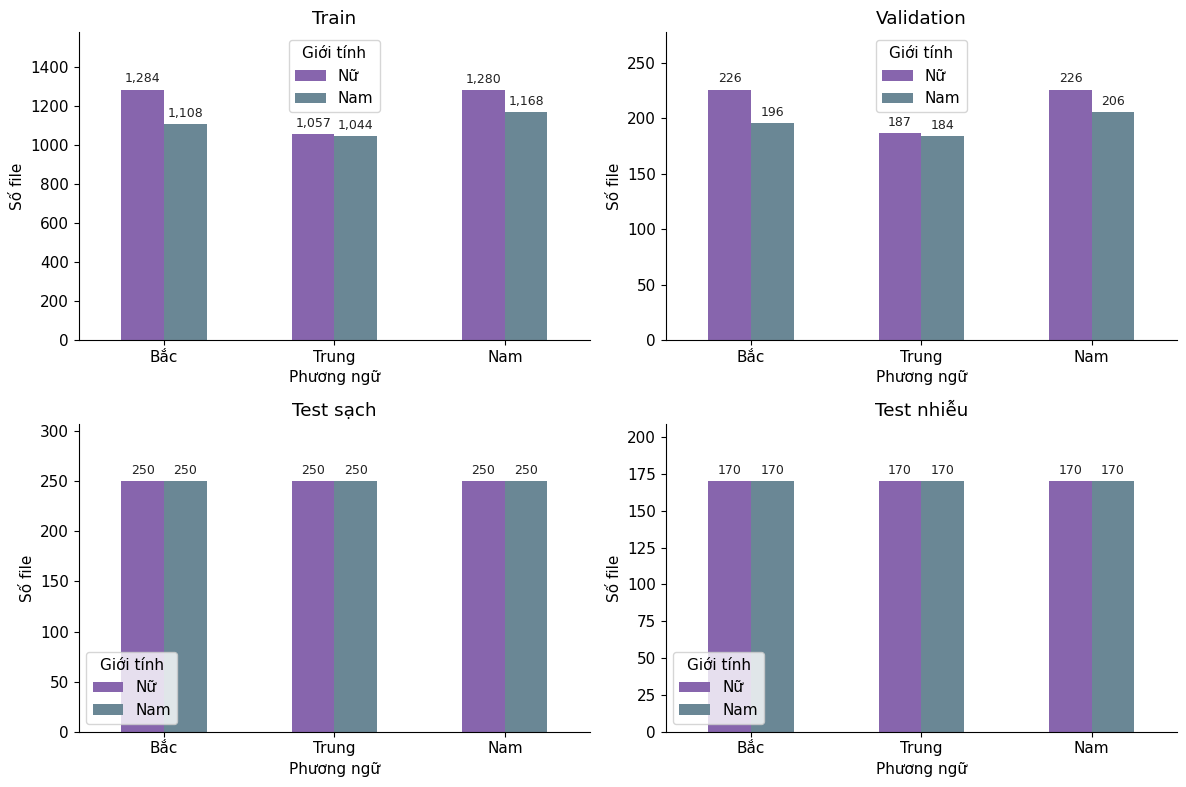

gender,Tập thực nghiệm,Phương ngữ,Nữ (%),Nam (%)
0,Test nhiễu,Trung,50.00,50.00
1,Test nhiễu,Bắc,50.00,50.00
2,Test nhiễu,Nam,50.00,50.00
3,Test sạch,Trung,50.00,50.00
4,Test sạch,Bắc,50.00,50.00
5,Test sạch,Nam,50.00,50.00
6,Train,Trung,50.31,49.69
7,Train,Bắc,53.68,46.32
8,Train,Nam,52.29,47.71
9,Validation,Trung,50.40,49.60


**Kết quả đọc được:** Tỉ lệ file nữ trong Train: Bắc 53.68%, Trung 50.31%, Nam 52.29%.

**Ý nghĩa với mô hình/đánh giá:** Đây là cơ sở mô tả thành phần dữ liệu và quyết định có cần bổ sung đánh giá theo giới tính hay không.

**Chưa thể kết luận:** Chưa biết mô hình có dùng giới tính làm dấu hiệu dự đoán phương ngữ; cần kiểm tra dự đoán theo nhóm để xác nhận.

In [5]:
gender_groups = splits.groupby(['split', 'gender', 'dialect']).size().rename('so_file').reset_index()
save_table('09_gender_dialect_groups', gender_groups)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes.flat, SPLITS):
    table = pd.crosstab(splits.loc[splits.split.eq(name), 'dialect'],
                        splits.loc[splits.split.eq(name), 'gender']).reindex(
                            index=REGIONS, columns=['Female', 'Male'], fill_value=0)
    table.rename(index=REGION_NAMES, columns={'Female': 'Nữ', 'Male': 'Nam'}).plot.bar(
        ax=ax, color=['#8765AD', '#6A8795'])
    label_bars(ax)
    ax.set(title=name, xlabel='Phương ngữ', ylabel='Số file')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Giới tính')
fig.tight_layout()
show_figure('figure02_gender_dialect', fig)
gender_percent = pd.crosstab([splits.split, splits.dialect], splits.gender).reindex(
    columns=['Female', 'Male'], fill_value=0)
gender_percent = gender_percent.div(gender_percent.sum(axis=1), axis=0) * 100
save_table('19_gender_percentages', gender_percent.round(2).reset_index())
female_train = gender_percent.loc['Train', 'Female'].reindex(REGIONS)
explain('Giới tính',
        'Tỉ lệ file nữ trong Train: ' + ', '.join(
            f'{REGION_NAMES[r]} {female_train[r]:.2f}%' for r in REGIONS) + '.',
        'Đây là cơ sở mô tả thành phần dữ liệu và quyết định có cần bổ sung đánh giá theo giới tính hay không.',
        'Chưa biết mô hình có dùng giới tính làm dấu hiệu dự đoán phương ngữ; cần kiểm tra dự đoán theo nhóm để xác nhận.')

## 5. Dữ liệu đa dạng người nói đến đâu, các tập có trùng người nói không?

**Phân tích gì?** (1) Số người nói theo miền; (2) số file mỗi người; (3) số file và người nói chung giữa các cặp tập.

**Vì sao cần?** 1.000 file từ 10 người khác với 1.000 file từ 100 người. Một số người đóng góp nhiều file có thể xuất hiện thường xuyên hơn trong huấn luyện. Nếu validation chứa người đã có trong train, kết quả validation không đại diện riêng cho khả năng nhận dạng người chưa gặp.

**Vì sao dùng cột và boxplot?** Cột so sánh số người nói giữa ba miền. Boxplot tóm tắt phân bố số file/người: đường giữa là trung vị, hộp chứa 50% người ở giữa; các điểm ngoài râu biểu thị giá trị xa theo quy tắc 1,5 lần khoảng tứ phân vị, không tự là dữ liệu lỗi. Bảng giao nhau dùng số chính xác, dễ hiểu hơn thêm một heatmap.

Kiểm tra dựa trên mã speaker trong metadata, giả định mã được dùng nhất quán giữa các tập. Nó không phát hiện audio bị đổi tên hoặc cùng video/phiên thu nếu thiếu thông tin đó.

dialect,Tập thực nghiệm,Bắc,Trung,Nam
0,Train,103,105,102
1,Validation,93,89,93
2,Test sạch,28,28,28
3,Test nhiễu,22,22,22


,Tập A,Tập B,File trùng,Người nói chung,File A của người nói chung,File B của người nói chung
0,Train,Validation,0,275,6645,1225
1,Train,Test sạch,0,0,0,0
2,Train,Test nhiễu,0,0,0,0
3,Validation,Test sạch,0,0,0,0
4,Validation,Test nhiễu,0,0,0,0
5,Test sạch,Test nhiễu,0,11,182,172


,Tập thực nghiệm,Mã người nói,Số file
0,Test nhiễu,SPK0312,16
1,Test nhiễu,SPK0321,15
2,Test nhiễu,SPK0332,15
3,Test nhiễu,SPK0334,19
4,Test nhiễu,SPK0339,20
5,Test nhiễu,SPK0340,19
6,Test nhiễu,SPK0344,10
7,Test nhiễu,SPK0353,17
8,Test nhiễu,SPK0373,13
9,Test nhiễu,SPK0375,13


Hiển thị 12/735 dòng. Bảng đầy đủ: 12_files_per_speaker.csv


,Tập thực nghiệm,Số người nói,Nhỏ nhất,Trung vị,Trung bình,Lớn nhất
0,Train,310,1,24.0,22.39,59
1,Validation,275,1,4.0,4.45,14
2,Test sạch,84,6,16.0,17.86,43
3,Test nhiễu,66,5,15.5,15.45,22


C:\Users\Uyen\AppData\Local\Temp\ipykernel_25780\3806534881.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([per_speaker.loc[per_speaker.split.eq(name), 'so_file'].to_numpy()


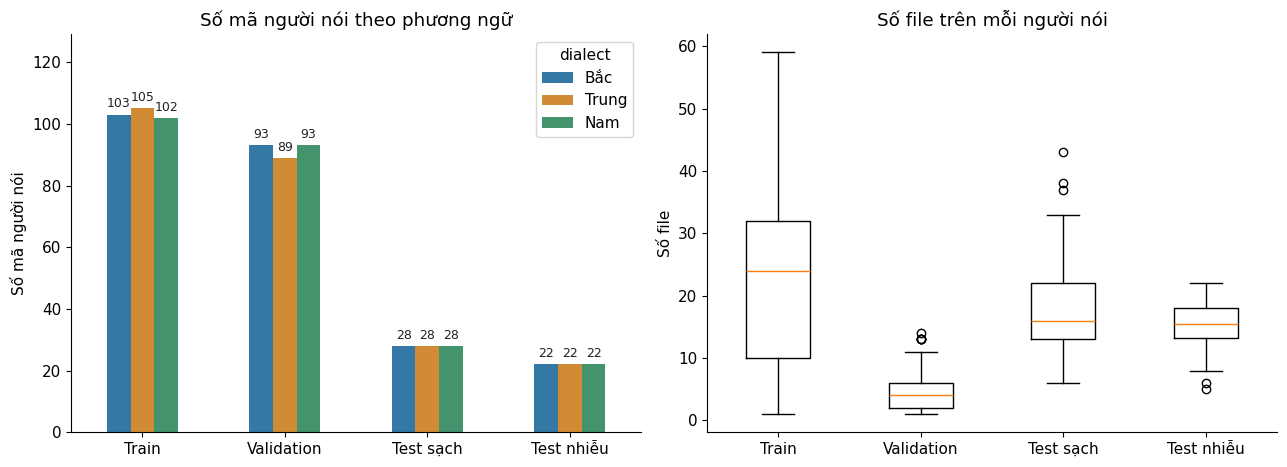

Cân bằng số file giữa các miền không có nghĩa mỗi người nói đóng góp bằng nhau.


**Kết quả đọc được:** Train–Validation trùng 0 tên file, chia sẻ 275 mã người nói. 100.00% file validation thuộc người đã xuất hiện trong Train.

**Ý nghĩa với mô hình/đánh giá:** Validation có người đã xuất hiện trong Train; dùng nó chọn checkpoint nhưng không gọi đây là đánh giá hoàn toàn trên người nói mới.

**Chưa thể kết luận:** Trùng người nói không đồng nghĩa trùng bản ghi và chưa định lượng mức tăng accuracy do điều đó. Cân bằng ba miền cũng không tự cân bằng các người nói trong từng miền.

In [6]:
speaker_counts = splits.groupby(['split', 'dialect']).speaker.nunique().unstack(fill_value=0)
speaker_counts = speaker_counts.reindex(index=SPLITS, columns=REGIONS)
save_table('10_speakers_by_dialect', speaker_counts.rename(columns=REGION_NAMES).reset_index())
overlap_rows = []
for left, right in combinations(SPLITS, 2):
    left_frame = splits[splits.split.eq(left)]
    right_frame = splits[splits.split.eq(right)]
    common_speakers = set(left_frame.speaker) & set(right_frame.speaker)
    overlap_rows.append({
        'tap_A': left, 'tap_B': right,
        'so_file_trung': len(set(left_frame.audio_name) & set(right_frame.audio_name)),
        'so_speaker_trung': len(common_speakers),
        'file_A_thuoc_speaker_chung': int(left_frame.speaker.isin(common_speakers).sum()),
        'file_B_thuoc_speaker_chung': int(right_frame.speaker.isin(common_speakers).sum()),
        'speaker_ids': ';'.join(sorted(common_speakers))})
overlaps = pd.DataFrame(overlap_rows)
save_table('11_split_overlap', overlaps)

per_speaker = splits.groupby(['split', 'speaker']).size().rename('so_file').reset_index()
save_table('12_files_per_speaker', per_speaker)
save_table('13_speaker_balance', per_speaker.groupby('split').so_file.agg(
    ['count', 'min', 'median', 'mean', 'max']).reindex(SPLITS).round(2).reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
speaker_counts.rename(columns=REGION_NAMES).plot.bar(ax=axes[0], color=COLORS)
axes[0].set(title='Số mã người nói theo phương ngữ', xlabel='', ylabel='Số mã người nói')
axes[0].tick_params(axis='x', rotation=0)
axes[1].boxplot([per_speaker.loc[per_speaker.split.eq(name), 'so_file'].to_numpy()
                 for name in SPLITS], labels=SPLITS, showfliers=True)
axes[1].set(title='Số file trên mỗi người nói', ylabel='Số file', xlabel='')
label_bars(axes[0])
fig.tight_layout()
show_figure('figure03_speaker_distribution', fig)
print('Cân bằng số file giữa các miền không có nghĩa mỗi người nói đóng góp bằng nhau.')

tv = overlaps[(overlaps.tap_A == 'Train') & (overlaps.tap_B == 'Validation')].iloc[0]
known_val_pct = 100 * int(tv.file_B_thuoc_speaker_chung) / len(sets['Validation'])
validation_message = (
    'Validation có người đã xuất hiện trong Train; dùng nó chọn checkpoint nhưng không gọi đây là đánh giá hoàn toàn trên người nói mới.'
    if tv.so_speaker_trung > 0 else
    'Không thấy mã người nói chung giữa Train và Validation; điều này hỗ trợ diễn giải đánh giá trên người nói chưa gặp theo metadata.')
explain('Người nói và bộ chia',
        f'Train–Validation trùng {int(tv.so_file_trung)} tên file, chia sẻ {int(tv.so_speaker_trung)} mã người nói. '
        f'{known_val_pct:.2f}% file validation thuộc người đã xuất hiện trong Train.',
        validation_message,
        'Trùng người nói không đồng nghĩa trùng bản ghi và chưa định lượng mức tăng accuracy do điều đó. '
        'Cân bằng ba miền cũng không tự cân bằng các người nói trong từng miền.')

## 6. Sampler thay đổi điều mô hình nhìn thấy như thế nào?

**Phân tích gì?** So sánh tỉ lệ file Train với tỉ lệ lượt lấy mẫu theo quy tắc sampler 1:2:1 và 1:1:1.

**Vì sao cần?** Đồ thị dataset gốc không cho biết miền nào được học nhiều lần. Ví dụ, Trung chiếm khoảng 30% file vẫn có thể chiếm 50% lượt học với sampler 1:2:1.

**Vì sao dùng cột phần trăm cạnh nhau?** Cả ba phân bố có cùng thang 0–100%, nên nhìn trực tiếp được mức sampler ưu tiên một miền. Đây là tỉ lệ lý thuyết của một epoch đầy đủ theo quy tắc hiện tại, không phải log đo lại lần train đang chạy.

Phần này thuộc **thiết lập đối chứng**, không phải đóng góp phương pháp. Giữ nguyên việc chọn checkpoint mỗi **306 bước**. Để xác nhận lượt lấy mẫu thực tế, dùng các cột đếm miền trong `training_history.csv` của lần train; cửa sổ log có thể cắt ngang epoch.

,Phương ngữ,File train duy nhất,Tỉ lệ file train (%),Lượt mỗi epoch sampler 1:2:1,Lượt mỗi epoch sampler 1:1:1,Tỉ lệ lượt 1:2:1 (%),Tỉ lệ lượt 1:1:1 (%)
0,Bắc,2392,34.46,2448,2448,25,33.33
1,Trung,2101,30.27,4896,2448,50,33.33
2,Nam,2448,35.27,2448,2448,25,33.33


Batch/epoch theo batch size 32: 1:2:1 = 306 ; 1:1:1 = 230
Đây là epoch đầy đủ. Epoch hoặc cửa sổ ghi log chưa đủ có thể lệch nhẹ.


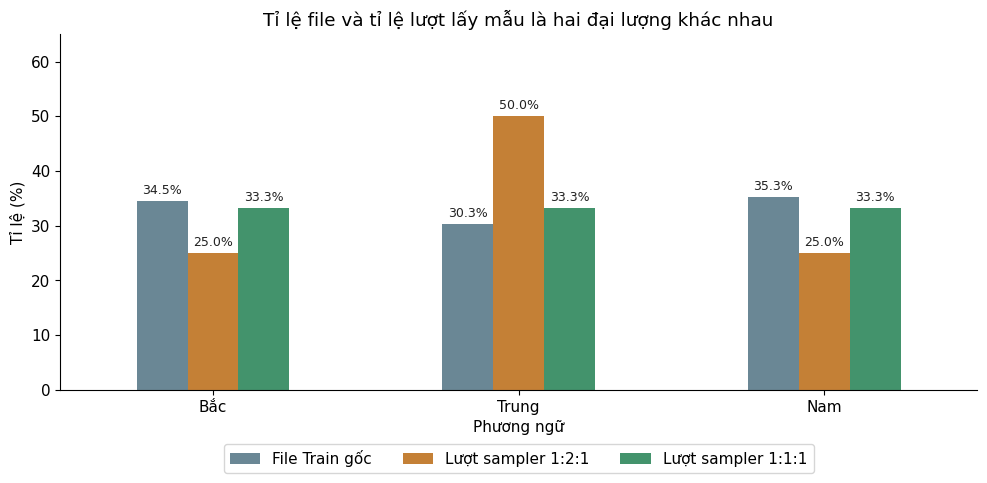

**Kết quả đọc được:** Trung chiếm 30.27% file Train; chiếm 50% lượt ở sampler 1:2:1 và 33,33% lượt ở sampler 1:1:1 trong epoch đầy đủ.

**Ý nghĩa với mô hình/đánh giá:** Đối chứng sampler kiểm tra ảnh hưởng của mức ưu tiên lớp; số file và số người nói gốc không đổi.

**Chưa thể kết luận:** Chưa thể nói sampler 1:2:1 gây lỗi khi thêm nhiễu hoặc 1:1:1 sẽ tốt hơn. Cần so sánh hai mô hình trên cùng bản ghi, nhiễu và SNR sau huấn luyện.

In [7]:
train_counts = counts.loc['Train'].reindex(REGIONS)
largest_class = int(train_counts.max())
sampler_table = pd.DataFrame({
    'Phương ngữ': [REGION_NAMES[r] for r in REGIONS],
    'File train duy nhất': train_counts.to_numpy(),
    'Tỉ lệ file train (%)': train_counts.to_numpy() / train_counts.sum() * 100,
    'Lượt mỗi epoch sampler 1:2:1': [largest_class, 2 * largest_class, largest_class],
    'Lượt mỗi epoch sampler 1:1:1': [largest_class] * 3,
    'Tỉ lệ lượt 1:2:1 (%)': [25, 50, 25],
    'Tỉ lệ lượt 1:1:1 (%)': [100 / 3] * 3})
save_table('14_sampler_exposure', sampler_table.round(2))
print('Batch/epoch theo batch size 32:',
      '1:2:1 =', int(np.ceil(4 * largest_class / 32)),
      '; 1:1:1 =', int(np.ceil(3 * largest_class / 32)))
print('Đây là epoch đầy đủ. Epoch hoặc cửa sổ ghi log chưa đủ có thể lệch nhẹ.')

exposure = pd.DataFrame({
    'File Train gốc': percentages.loc['Train'],
    'Lượt sampler 1:2:1': [25, 50, 25],
    'Lượt sampler 1:1:1': [100/3] * 3}, index=REGIONS)
fig, ax = plt.subplots(figsize=(10, 5))
exposure.rename(index=REGION_NAMES).plot.bar(ax=ax, color=['#6A8795', '#C48036', '#43936C'])
label_bars(ax, percent=True)
ax.set(title='Tỉ lệ file và tỉ lệ lượt lấy mẫu là hai đại lượng khác nhau',
       xlabel='Phương ngữ', ylabel='Tỉ lệ (%)', ylim=(0, 65))
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
fig.tight_layout()
show_figure('figure05_sampler_exposure', fig)
explain('Sampler',
        f'Trung chiếm {percentages.loc["Train", "Central"]:.2f}% file Train; '
        'chiếm 50% lượt ở sampler 1:2:1 và 33,33% lượt ở sampler 1:1:1 trong epoch đầy đủ.',
        'Đối chứng sampler kiểm tra ảnh hưởng của mức ưu tiên lớp; số file và số người nói gốc không đổi.',
        'Chưa thể nói sampler 1:2:1 gây lỗi khi thêm nhiễu hoặc 1:1:1 sẽ tốt hơn. '
        'Cần so sánh hai mô hình trên cùng bản ghi, nhiễu và SNR sau huấn luyện.')

## 7. Audio dài/ngắn thế nào so với đầu vào mô hình? — tùy chọn

**Phân tích gì?** Thời lượng gốc, tổng số giờ đã đo, tần số lấy mẫu và số kênh; tỉ lệ file ngắn hơn/dài hơn độ dài đầu vào trước augmentation.

**Vì sao cần?** `dataset.py` lấy đoạn đầu với file dài và lặp âm thanh (`wrap`) với file ngắn. File dài có thể có lời nói phía sau không được sử dụng; lặp file ngắn không tạo thông tin lời nói mới. Thống kê này giải thích lựa chọn tiền xử lý và hạn chế của nó.

**Vì sao dùng histogram?** Thời lượng là số liên tục. Histogram cho biết nhiều file nằm trong khoảng giây nào; bốn hình dùng chung ranh giới bin và thang thời gian. Đường đứt là độ dài đầu vào tính từ cấu hình hiện tại, xấp xỉ 5 giây; không phải thời lượng gốc của mọi file.

Giữ `READ_AUDIO_INFO = False` khi đang train. Khi muốn bổ sung phần này, đổi thành `True` rồi chạy lại notebook. Chỉ đọc thông tin audio, không gọi mô hình, không sửa dữ liệu. Nếu có file không đọc được, báo cáo độ phủ phép đo; tổng giờ lúc đó chỉ là tổng của phần đã đọc.

In [8]:
audio_info = None
if not READ_AUDIO_INFO:
    print('Chưa đo thời lượng audio. Không đưa thời lượng thực đo vào luận từ lần chạy này.')
else:
    import soundfile as sf
    from tqdm.auto import tqdm
    records = []
    for row in tqdm(metadata.itertuples(index=False), total=len(metadata), desc='Đọc thông tin audio'):
        record = {'audio_name': row.audio_name}
        try:
            info = sf.info(row.audio_path)
            duration = info.frames / info.samplerate
            if duration <= 0:
                raise ValueError('Audio không có thời lượng dương')
            record.update(duration_seconds=duration, sample_rate=info.samplerate,
                          channels=info.channels, error='')
        except Exception as error:
            record.update(duration_seconds=np.nan, sample_rate=np.nan, channels=np.nan, error=str(error))
        records.append(record)
    audio_info = pd.DataFrame(records)
    save_table('15_audio_info', audio_info)
    failures = audio_info[audio_info.error.ne('')]
    save_table('16_audio_info_errors', failures)
    timed = splits.merge(audio_info, on='audio_name', validate='many_to_one')
    duration_summary = timed.groupby('split').agg(
        total_files=('audio_name', 'size'), measured_files=('duration_seconds', 'count'),
        total_measured_seconds=('duration_seconds', lambda x: x.sum(min_count=1)),
        min_seconds=('duration_seconds', 'min'), mean_seconds=('duration_seconds', 'mean'),
        median_seconds=('duration_seconds', 'median'), max_seconds=('duration_seconds', 'max')).reindex(SPLITS)
    duration_summary['coverage_pct'] = duration_summary.measured_files / duration_summary.total_files * 100
    duration_summary['measured_hours'] = duration_summary.total_measured_seconds / 3600
    save_table('17_duration_summary', duration_summary.round(3).reset_index())
    save_table('18_sample_rate_channels',
               audio_info.groupby(['sample_rate', 'channels']).size().rename('so_file').reset_index())
    if not failures.empty:
        print('Có file chưa đo được. Thời lượng tổng chỉ của phần đã đọc, chưa phải toàn dataset.')
    import yaml
    config_path = PROJECT / 'config_train_sampler111.yaml'
    hashes[str(config_path.relative_to(ROOT))] = file_hash(config_path)
    config = yaml.safe_load(config_path.read_text(encoding='utf-8-sig'))
    audio_config = config['audio']
    sr = audio_config['sampling_rate']
    _, window_len, step_size = audio_config['window_configs'][sr]
    input_seconds = (audio_config['length'] * 100 * step_size + window_len - step_size) / sr
    measured = timed[timed.duration_seconds.notna()].copy()
    measured['shorter'] = measured.duration_seconds.lt(input_seconds)
    measured['longer'] = measured.duration_seconds.gt(input_seconds)
    handling = measured.groupby('split').agg(
        measured_files=('audio_name', 'size'), shorter_pct=('shorter', 'mean'), longer_pct=('longer', 'mean')).reindex(SPLITS)
    handling[['shorter_pct', 'longer_pct']] *= 100
    save_table('20_duration_vs_input', handling.round(2).reset_index())
    # Xấp xỉ từ header audio gốc; số mẫu sau resample có thể chênh rất nhỏ ở biên.
    values_all = measured.duration_seconds.to_numpy()
    max_seconds = max(float(values_all.max()) if len(values_all) else 0, input_seconds) * 1.05
    shared_bins = np.linspace(0, max_seconds, 26)
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for axis, name in zip(axes.flat, SPLITS):
        values = timed.loc[timed.split.eq(name), 'duration_seconds'].dropna()
        axis.hist(values, bins=shared_bins, color='#3478A5')
        axis.axvline(input_seconds, color='#C48036', linestyle='--', label=f'Đầu vào ~{input_seconds:.3f}s')
        axis.set_xlim(0, max_seconds)
        axis.legend(fontsize=8)
        axis.set(title=name, xlabel='Thời lượng gốc (giây)', ylabel='Số file')
    fig.tight_layout()
    show_figure('figure04_audio_duration', fig)

    explain('Thời lượng',
            f'Đọc được {audio_info.duration_seconds.notna().sum():,}/{len(audio_info):,} file. '
            f'Độ dài đầu vào trước augmentation tính từ cấu hình là {input_seconds:.3f} giây.',
            'Bảng file ngắn/dài cho biết bao nhiêu dữ liệu có thể chịu thao tác lặp/cắt trong pipeline hiện tại; '
            'tỉ lệ chỉ tính trên các file đo được.',
            'Độ dài khác nhau chưa chứng minh nguyên nhân lỗi theo miền. Header audio không đo được SNR, '
            'tỉ lệ khoảng lặng hoặc lượng lời nói có ích trong file.')

Chưa đo thời lượng audio. Không đưa thời lượng thực đo vào luận từ lần chạy này.


## Phụ lục kiểm tra nguồn: metadata có khớp paper không?

Đối chiếu đúng phạm vi: 8.166 file của paper là **train trước khi tách validation**. Bảng 3 paper ghi 1.509 file nữ miền Bắc, trong khi metadata đã kiểm tra trước đây có 1.510. Ô dưới tính lại chênh lệch; không sửa dữ liệu để làm cho số khớp.

Dùng bảng đối chiếu để giải thích phiên bản dữ liệu. Một sai khác số đếm chưa đủ kết luận ảnh hưởng tới accuracy. Nếu metadata không khớp đáng kể hoặc mã người nói có nhiều nhãn, cần rà soát trước khi dùng bản nháp cuối notebook.

In [9]:
paper_overview = pd.DataFrame({
    'corpus': ['Train gốc', 'Test sạch', 'Test nhiễu'],
    'paper_files': [8166, 1500, 1020],
    'paper_speakers': [310, 84, 66]})
actual = metadata.groupby('corpus').agg(
    actual_files=('audio_name', 'size'), actual_speakers=('speaker', 'nunique')).reset_index()
comparison = paper_overview.merge(actual, on='corpus', validate='one_to_one')
comparison['file_difference'] = comparison.actual_files - comparison.paper_files
comparison['speaker_difference'] = comparison.actual_speakers - comparison.paper_speakers
save_table('05_paper_comparison', comparison)

paper_groups = pd.DataFrame([
    ['Male', 'North', 1304], ['Male', 'Central', 1228], ['Male', 'South', 1374],
    ['Female', 'North', 1509], ['Female', 'Central', 1244], ['Female', 'South', 1506]
], columns=['gender', 'dialect', 'paper_files'])
actual_groups = metadata[metadata.corpus.eq('Train gốc')].groupby(
    ['gender', 'dialect']).size().rename('actual_files').reset_index()
group_comparison = paper_groups.merge(actual_groups, on=['gender', 'dialect'], how='outer')
group_comparison['difference'] = group_comparison.actual_files - group_comparison.paper_files
save_table('06_paper_training_groups', group_comparison)
print('Tổng mã speaker trong metadata:', metadata.speaker.nunique(), '| Paper: 449')
print('Tổng các ô file train trong Bảng 3 paper:', paper_groups.paper_files.sum(),
      '| Tổng train trong Bảng 2: 8166')

,Tập gốc,Số file (paper),Người nói (paper),Số file (metadata),Người nói (metadata),Chênh lệch file,Chênh lệch người nói
0,Train gốc,8166,310,8166,310,0,0
1,Test sạch,1500,84,1500,84,0,0
2,Test nhiễu,1020,66,1020,66,0,0


,Giới tính,Phương ngữ,Số file (paper),Số file (metadata),Chênh lệch file
0,Nữ,Trung,1244,1244,0
1,Nữ,Bắc,1509,1510,1
2,Nữ,Nam,1506,1506,0
3,Nam,Trung,1228,1228,0
4,Nam,Bắc,1304,1304,0
5,Nam,Nam,1374,1374,0


Tổng mã speaker trong metadata: 449 | Paper: 449
Tổng các ô file train trong Bảng 3 paper: 8165 | Tổng train trong Bảng 2: 8166


## 8. Tổng hợp để đưa vào luận văn

Ô dưới tạo **bảng nối kết quả dữ liệu với thiết kế thí nghiệm**, sau đó xuất bản nháp có số liệu lấy từ chính lần chạy này. Nhận xét luôn tách điều đã đếm được và điều còn cần thí nghiệm; không viết trước kết luận mô hình mới tốt hơn.

**Bộ nội dung chính đề nghị:** bảng tổng quan bốn tập, Hình 1 phân bố ba miền, bảng trùng người nói và đoạn mô tả tiền xử lý. Đưa Hình 5 về sampler vào thiết lập thực nghiệm. Hình giới tính/boxplot người nói có thể để phụ lục nếu không bàn sâu. Chỉ thêm hình thời lượng khi đã đọc audio và kiểm tra độ phủ.

In [10]:
evidence = pd.DataFrame([
    {'Phân tích': key, 'Kết quả quan sát': value[0],
     'Ý nghĩa với thiết kế thí nghiệm': value[1], 'Chưa thể kết luận': value[2]}
    for key, value in insights.items()])
save_table('thesis_table02_evidence_and_implications', evidence)

,Phân tích,Kết quả quan sát,Ý nghĩa với thiết kế thí nghiệm,Chưa thể kết luận
0,Nguồn dữ liệu,"Metadata có 10,686 file và 449 mã người nói du...",Số file thể hiện quy mô mẫu; số người nói bổ s...,Nhiều file không tự bảo đảm nhiều giọng độc lậ...
1,Bộ chia,"Train gồm 6,941 file, validation 1,225 file; h...",Có thể báo cáo rõ dữ liệu dùng học và dữ liệu ...,Không trùng tên file chưa đồng nghĩa không trù...
2,Phân bố phương ngữ,"Train: Bắc 2,392 file (34.46%), Trung 2,101 fi...","Báo cáo cả accuracy, macro-F1 và recall từng m...",Chỉ đếm file chưa chứng minh miền ít file khó ...
3,Giới tính,"Tỉ lệ file nữ trong Train: Bắc 53.68%, Trung 5...",Đây là cơ sở mô tả thành phần dữ liệu và quyết...,Chưa biết mô hình có dùng giới tính làm dấu hi...
4,Người nói và bộ chia,"Train–Validation trùng 0 tên file, chia sẻ 275...",Validation có người đã xuất hiện trong Train; ...,Trùng người nói không đồng nghĩa trùng bản ghi...
5,Sampler,Trung chiếm 30.27% file Train; chiếm 50% lượt ...,Đối chứng sampler kiểm tra ảnh hưởng của mức ư...,Chưa thể nói sampler 1:2:1 gây lỗi khi thêm nh...


In [11]:
n_total = len(metadata)
n_people = metadata.speaker.nunique()
n_base = len(train_original)
n_train, n_val = len(sets['Train']), len(sets['Validation'])
tv = overlaps[(overlaps.tap_A == 'Train') & (overlaps.tap_B == 'Validation')].iloc[0]
train_ids = set(splits.loc[splits.split.eq('Train'), 'speaker'])
val_ids = set(splits.loc[splits.split.eq('Validation'), 'speaker'])
test_ids = set(splits.loc[splits.split.isin(['Test sạch', 'Test nhiễu']), 'speaker'])
dev_test_overlap = len((train_ids | val_ids) & test_ids)
split_file_overlap = int(overlaps.so_file_trung.sum())

paragraphs = [
    '# Bản nháp mô tả ViSpeech và bộ chia hiện tại',
    f'Nghiên cứu sử dụng bộ dữ liệu ViSpeech của Nguyen và cộng sự (2024). '
    f'Theo metadata cục bộ được kiểm tra, dữ liệu gồm {n_total:,} file audio và '
    f'{n_people:,} mã người nói duy nhất, có nhãn giới tính và ba phương ngữ Bắc, Trung, Nam.',
    f'Tập train gốc gồm {n_base:,} file, được tách thành {n_train:,} file huấn luyện '
    f'({100*n_train/n_base:.2f}%) và {n_val:,} file validation ({100*n_val/n_base:.2f}%). '
    f'Tập test sạch gồm {len(sets["Test sạch"]):,} file và tập test nhiễu gồm '
    f'{len(sets["Test nhiễu"]):,} file. Validation được dùng trong quá trình phát triển; '
    'hai tập test dành cho đánh giá kết quả sau khi chốt phương pháp.',
    f'Đối chiếu các danh sách cho thấy tổng số giao nhau theo tên file trên các cặp tập là '
    f'{split_file_overlap}. Train và validation chia sẻ {int(tv.so_speaker_trung)} mã người nói. '
    f'Hợp Train/Validation và hợp hai tập test chia sẻ {dev_test_overlap} mã người nói.'
]
if tv.so_speaker_trung > 0:
    paragraphs.append('Do có người nói xuất hiện trong cả train và validation, kết quả validation '
                      'không được diễn giải riêng như khả năng tổng quát hóa sang người nói chưa gặp.')
paragraphs.append('Kiểm tra trên dựa vào tên file và mã speaker trong metadata, chưa kiểm tra bản sao '
                  'âm thanh đổi tên hoặc sự trùng lặp video/phiên thu. Không cộng số người nói của '
                  'các tập để suy ra tổng số người độc lập.')
paragraphs.append('Trong đối chứng sampler, kiến trúc và pipeline âm thanh của baseline được giữ nguyên. '
                  'Sampler 1:2:1 ưu tiên lượt lấy mẫu miền Trung; sampler 1:1:1 cân bằng lượt lấy mẫu '
                  'ba miền theo epoch đầy đủ. Đây là thay đổi tần suất tiếp xúc dữ liệu, không làm tăng '
                  'số file hoặc số người nói duy nhất.')
if audio_info is None:
    paragraphs.append('Thời lượng audio chưa được đo trong lần phân tích này; cần bổ sung kết quả '
                      'đo trước khi trình bày thống kê thời lượng thực tế.')
elif audio_info.error.ne('').any():
    paragraphs.append('Một số file chưa đọc được thông tin audio; các thống kê thời lượng hiện chỉ '
                      'áp dụng cho những file đã đo thành công.')
else:
    paragraphs.append(f'Tổng thời lượng audio gốc đo được trên toàn bộ file metadata là '
                      f'{audio_info.duration_seconds.sum()/3600:.3f} giờ. '
                      'Đây là tổng thời lượng file, không phải thời lượng sau cắt/lặp để đưa vào model.')
paragraphs += [
    'Nguồn: Nguyen et al. (2024), Gender and Dialect Classification for the Vietnamese Language. '
    'https://aclanthology.org/2024.paclic-1.39.pdf',
    'Trước khi dùng: xem 05_paper_comparison.csv và 06_paper_training_groups.csv để ghi rõ '
    'sai khác giữa metadata và bảng trong paper, nếu có.'
]
paragraphs.append('## Phân tích phân bố và ý nghĩa với thiết kế thực nghiệm')
for key in ['Phân bố phương ngữ', 'Giới tính', 'Người nói và bộ chia', 'Sampler', 'Thời lượng']:
    if key in insights:
        observation, implication, limit = insights[key]
        paragraphs.append(f'### {key}\n\n{observation} {implication}\n\nGiới hạn diễn giải: {limit}')
differences = group_comparison[group_comparison.difference.ne(0)]
if not differences.empty:
    details = '; '.join(f'{row.gender}/{row.dialect}: metadata {int(row.actual_files)}, '
                        f'paper {int(row.paper_files)}' for row in differences.dropna().itertuples())
    paragraphs.append('Đối chiếu Bảng 3 paper có sai khác ở nhóm: ' + details +
                      '. Thống kê thực nghiệm sử dụng số đếm từ metadata cục bộ.')
paragraphs.append('Hai tập test sạch và nhiễu không được xem là các cặp bản gốc–bản thêm nhiễu của cùng '
                  'một câu chỉ dựa trên tên tập. Đánh giá tác động của nhiễu có kiểm soát cần '
                  'các cặp cùng audio gốc, nguồn nhiễu và SNR được cố định.')
draft = '\n\n'.join(paragraphs)
(OUT / 'draft_dataset_section.md').write_text(draft, encoding='utf-8')
display(Markdown(draft))

captions = '''# Gợi ý chú thích hình
- Hình 1: Phân bố số lượng và tỉ lệ file theo phương ngữ trong các tập dữ liệu thực nghiệm.
- Hình 2: Số file trong sáu nhóm kết hợp giới tính và phương ngữ.
- Hình 3: Số mã người nói theo phương ngữ và phân bố số file trên mỗi người nói.
- Hình 5: So sánh tỉ lệ file Train và tỉ lệ lượt lấy mẫu lý thuyết của hai sampler; không phải dự đoán của mô hình.
- Hình 4 (nếu đã đo): Phân bố thời lượng file audio gốc; cần báo cáo độ phủ phép đo.

Nguồn hình: tác giả luận văn thống kê từ metadata/danh sách dữ liệu ViSpeech đang sử dụng.
Trong chương Dữ liệu nên ưu tiên Hình 1 và bảng bộ chia; thêm Hình 3 nếu bàn về người nói.
Không cần đưa tất cả hình vào nội dung chính; bảng chi tiết có thể để phụ lục.
'''
(OUT / 'figure_captions.md').write_text(captions, encoding='utf-8')
(OUT / 'analysis_info.json').write_text(json.dumps({
    'created_at': datetime.now().isoformat(), 'project': str(ROOT), 'input_sha256': hashes,
    'read_audio_info': READ_AUDIO_INFO, 'check_audio_paths': CHECK_AUDIO_PATHS,
    'pandas': pd.__version__, 'numpy': np.__version__,
    'note': 'Metadata/list analysis only; no model evaluation or training.'
}, ensure_ascii=False, indent=2), encoding='utf-8')
print('Bảng CSV, hình PNG/PDF, đoạn mô tả và thông tin nguồn đã lưu tại:', OUT)

# Bản nháp mô tả ViSpeech và bộ chia hiện tại

Nghiên cứu sử dụng bộ dữ liệu ViSpeech của Nguyen và cộng sự (2024). Theo metadata cục bộ được kiểm tra, dữ liệu gồm 10,686 file audio và 449 mã người nói duy nhất, có nhãn giới tính và ba phương ngữ Bắc, Trung, Nam.

Tập train gốc gồm 8,166 file, được tách thành 6,941 file huấn luyện (85.00%) và 1,225 file validation (15.00%). Tập test sạch gồm 1,500 file và tập test nhiễu gồm 1,020 file. Validation được dùng trong quá trình phát triển; hai tập test dành cho đánh giá kết quả sau khi chốt phương pháp.

Đối chiếu các danh sách cho thấy tổng số giao nhau theo tên file trên các cặp tập là 0. Train và validation chia sẻ 275 mã người nói. Hợp Train/Validation và hợp hai tập test chia sẻ 0 mã người nói.

Do có người nói xuất hiện trong cả train và validation, kết quả validation không được diễn giải riêng như khả năng tổng quát hóa sang người nói chưa gặp.

Kiểm tra trên dựa vào tên file và mã speaker trong metadata, chưa kiểm tra bản sao âm thanh đổi tên hoặc sự trùng lặp video/phiên thu. Không cộng số người nói của các tập để suy ra tổng số người độc lập.

Trong đối chứng sampler, kiến trúc và pipeline âm thanh của baseline được giữ nguyên. Sampler 1:2:1 ưu tiên lượt lấy mẫu miền Trung; sampler 1:1:1 cân bằng lượt lấy mẫu ba miền theo epoch đầy đủ. Đây là thay đổi tần suất tiếp xúc dữ liệu, không làm tăng số file hoặc số người nói duy nhất.

Thời lượng audio chưa được đo trong lần phân tích này; cần bổ sung kết quả đo trước khi trình bày thống kê thời lượng thực tế.

Nguồn: Nguyen et al. (2024), Gender and Dialect Classification for the Vietnamese Language. https://aclanthology.org/2024.paclic-1.39.pdf

Trước khi dùng: xem 05_paper_comparison.csv và 06_paper_training_groups.csv để ghi rõ sai khác giữa metadata và bảng trong paper, nếu có.

## Phân tích phân bố và ý nghĩa với thiết kế thực nghiệm

### Phân bố phương ngữ

Train: Bắc 2,392 file (34.46%), Trung 2,101 file (30.27%), Nam 2,448 file (35.27%). Lớp nhiều nhất/ít nhất = 1.17 lần. Chênh lệch tỉ lệ train–validation lớn nhất là 0.02 điểm phần trăm. Báo cáo cả accuracy, macro-F1 và recall từng miền để thấy lớp nào bị bỏ sót; dùng bảng sampler ở phần 6 để phân biệt tỉ lệ file với tỉ lệ lượt học.

Giới hạn diễn giải: Chỉ đếm file chưa chứng minh miền ít file khó hơn, hay sampler gây dự đoán lệch sang Trung khi có nhiễu.

### Giới tính

Tỉ lệ file nữ trong Train: Bắc 53.68%, Trung 50.31%, Nam 52.29%. Đây là cơ sở mô tả thành phần dữ liệu và quyết định có cần bổ sung đánh giá theo giới tính hay không.

Giới hạn diễn giải: Chưa biết mô hình có dùng giới tính làm dấu hiệu dự đoán phương ngữ; cần kiểm tra dự đoán theo nhóm để xác nhận.

### Người nói và bộ chia

Train–Validation trùng 0 tên file, chia sẻ 275 mã người nói. 100.00% file validation thuộc người đã xuất hiện trong Train. Validation có người đã xuất hiện trong Train; dùng nó chọn checkpoint nhưng không gọi đây là đánh giá hoàn toàn trên người nói mới.

Giới hạn diễn giải: Trùng người nói không đồng nghĩa trùng bản ghi và chưa định lượng mức tăng accuracy do điều đó. Cân bằng ba miền cũng không tự cân bằng các người nói trong từng miền.

### Sampler

Trung chiếm 30.27% file Train; chiếm 50% lượt ở sampler 1:2:1 và 33,33% lượt ở sampler 1:1:1 trong epoch đầy đủ. Đối chứng sampler kiểm tra ảnh hưởng của mức ưu tiên lớp; số file và số người nói gốc không đổi.

Giới hạn diễn giải: Chưa thể nói sampler 1:2:1 gây lỗi khi thêm nhiễu hoặc 1:1:1 sẽ tốt hơn. Cần so sánh hai mô hình trên cùng bản ghi, nhiễu và SNR sau huấn luyện.

Đối chiếu Bảng 3 paper có sai khác ở nhóm: Female/North: metadata 1510, paper 1509. Thống kê thực nghiệm sử dụng số đếm từ metadata cục bộ.

Hai tập test sạch và nhiễu không được xem là các cặp bản gốc–bản thêm nhiễu của cùng một câu chỉ dựa trên tên tập. Đánh giá tác động của nhiễu có kiểm soát cần các cặp cùng audio gốc, nguồn nhiễu và SNR được cố định.

Bảng CSV, hình PNG/PDF, đoạn mô tả và thông tin nguồn đã lưu tại: c:\Users\Uyen\Documents\Master\LuanVan01\Report\Dataset_Analysis\20261019_110129_396978


## 9. Cách đọc và sử dụng kết quả sau khi chạy

1. Xem các kiểm tra metadata/nhãn. Nếu ô báo lỗi, giải quyết nguồn sai khác trước khi trích số liệu.
2. Đọc bảng tổng quan và Hình 1 để viết quy mô, bộ chia và mức cân bằng ba miền.
3. Đọc bảng giao nhau người nói để mô tả đúng phạm vi khái quát của validation/test. Không tự đổi bộ chia của lần train đang chạy từ notebook này.
4. Đưa bảng/hình sampler vào phần thiết lập thực nghiệm, tách khỏi số file gốc của dataset.
5. Sau khi train xong, bật phần thời lượng nếu cần hoàn thiện mô tả audio và tiền xử lý.
6. Lấy `draft_dataset_section.md` làm bản nháp; biên tập lại theo văn phong luận, bổ sung trích dẫn. Dùng PNG/PDF được xuất thay vì chụp màn hình notebook.

**Vì sao không chép heatmap tương quan nhãn từ notebook VIVOS?** Bắc/Trung/Nam là nhãn phân loại, không có khoảng cách số học 1–2–3. Tương quan giữa MFCC và con số gán cho miền thay đổi theo cách đánh mã, không chứng minh đặc trưng phân biệt miền. MFCC minh họa trong notebook đó cũng không thay cho bộ Log-Mel/Delta/Delta² của baseline hiện tại.

**Bước tiếp theo về nghiên cứu:** phân tích dự đoán trên cùng bản ghi trước/sau nhiễu để đo lỗi mới, rồi so sánh sampler khi model mới hoàn tất. Phần đó thuộc kết quả thực nghiệm; các biểu đồ dataset ở đây chưa xác nhận nguyên nhân lệch dự đoán.